# ChunkyBERT evaluation on `stories_10k.jsonl`

Applies the ChunkyBERT political-bias classifier (Loiya et al., *Sci. Rep.* 16, 15323 (2026)),
trained here on the Article-Bias-Prediction corpus (Baly et al.) to 85.7% validation accuracy / 0.962 AUC.

**The file holds 10,000 stories, and each story carries four different texts:**

| Field | What it is | Bias label |
|---|---|---|
| `left` | source article from a left-leaning outlet | Left (0) |
| `center` | source article from a centre outlet | Centre (1) |
| `right` | source article from a right-leaning outlet | Right (2) |
| `neutral` | LLM-generated neutral summary of the story | none — generated text, no label |

So 30,000 of the texts are **labelled source articles** (evaluated against ground truth below)
and 10,000 are **unlabelled neutral summaries** (scored separately in section 5).
Only that last field is "neutral" — the other three are ordinary partisan news articles.

Every section reports the **full probability vector over all three classes**, not just the argmax.

Provenance: downloaded from `RaunakSeksaria/ANLP-Project` as `neutral_articles_10k.jsonl`;
renamed locally to `stories_10k.jsonl` because most of its articles are not neutral.

In [1]:
import json, sys, math
import numpy as np, pandas as pd, torch
from pathlib import Path
from transformers import BertTokenizer
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, ConfusionMatrixDisplay)

ROOT = Path("/root/ANLP/ANLP-Project")
sys.path.insert(0, str(ROOT / "chunkybert"))
from model import ChunkedBERTClassifier

WEIGHTS = ROOT / "models/chunkybert_5ep.pt"
DATA    = ROOT / "data/stories_10k.jsonl"
CLASSES = ["Left", "Centre", "Right"]      # label ids 0, 1, 2 — same order as training
SLOT2ID = {"left": 0, "center": 1, "right": 2}
BATCH, MAX_LEN = 16, 5000

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

cuda NVIDIA GeForce RTX 3050 Laptop GPU


## 1. Load model and data

In [2]:
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
model = ChunkedBERTClassifier(num_classes=3)
model.load_state_dict(torch.load(WEIGHTS, map_location="cpu", weights_only=True))
model.eval().to(device)

stories = [json.loads(l) for l in DATA.open(encoding="utf-8") if l.strip()]
print(f"{len(stories)} stories")

# Labelled source articles: one row per (story, slot)
src = pd.DataFrame([
    {"story_id": s["story_id"], "split": s.get("split"), "slot": slot,
     "label": SLOT2ID[slot], "publisher": s[slot]["publisher"],
     "article_id": s[slot]["article_id"], "text": s[slot]["body"]}
    for s in stories for slot in ("left", "center", "right")
])
# Unlabelled generated summaries: one row per story
summ = pd.DataFrame([{"story_id": s["story_id"], "split": s.get("split"),
                      "text": s["neutral"]} for s in stories])

print(f"labelled source articles: {len(src)}   unlabelled neutral summaries: {len(summ)}")
src.label.value_counts().rename(index=dict(enumerate(CLASSES))).to_frame("articles")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


10000 stories
labelled source articles: 30000   unlabelled neutral summaries: 10000


,articles
label,
Left,10000
Centre,10000
Right,10000


## 2. Score every text

Softmax over the three logits gives each article's probability for Left, Centre and Right.

In [3]:
@torch.no_grad()
def score(texts, batch=BATCH, tag=""):
    out = []
    for i in range(0, len(texts), batch):
        enc = tokenizer(texts[i:i+batch], return_tensors="pt", truncation=True,
                        max_length=MAX_LEN, padding=True)
        ids, mask = enc["input_ids"].to(device), enc["attention_mask"].to(device)
        with torch.autocast("cuda", enabled=device.type == "cuda"):
            logits = model(ids, mask, tokenizer)
        out.append(torch.softmax(logits.float(), dim=1).cpu())
        if (i // batch) % 200 == 0:
            print(f"  {tag} {i:>6}/{len(texts)}", flush=True)
    return torch.cat(out).numpy()

def attach(df, probs):
    df = df.copy()
    df[["p_left", "p_centre", "p_right"]] = probs
    df["pred_id"]    = probs.argmax(1)
    df["pred"]       = [CLASSES[i] for i in df.pred_id]
    df["confidence"] = probs.max(1)
    s = np.sort(probs, axis=1)
    df["margin"]  = s[:, -1] - s[:, -2]
    df["entropy"] = -(probs * np.log(probs + 1e-12)).sum(1) / math.log(3)
    return df

src  = attach(src,  score(src.text.tolist(),  tag="sources"))
summ = attach(summ, score(summ.text.tolist(), tag="summaries"))

src.drop(columns="text").to_csv(ROOT / "evaluation/scores/source_article_scores.csv", index=False)
summ.drop(columns="text").to_csv(ROOT / "evaluation/scores/neutral_summary_scores.csv", index=False)
src[["story_id", "slot", "publisher", "p_left", "p_centre", "p_right", "pred", "confidence"]].head(12)

  sources      0/30000


  sources   3200/30000


  sources   6400/30000


  sources   9600/30000


  sources  12800/30000


...

  summaries      0/10000


  summaries   3200/10000


  summaries   6400/10000


  summaries   9600/10000


,story_id,slot,publisher,p_left,p_centre,p_right,pred,confidence
0,1000122,left,cnn,9.999777e-01,0.000022,6.252099e-07,Left,0.999978
1,1000122,center,hill,9.918861e-01,0.004957,3.156956e-03,Left,0.991886
2,1000122,right,breitbart,3.819123e-01,0.034887,5.832004e-01,Right,0.583200
3,1000196,left,nyt,9.866588e-01,0.013000,3.414938e-04,Left,0.986659
4,1000196,center,ap,1.754247e-05,0.005540,9.944424e-01,Right,0.994442
5,1000196,right,fox,7.014604e-08,0.000030,9.999698e-01,Right,0.999970
6,100020,left,dailykos,9.898538e-01,0.003948,6.198548e-03,Left,0.989854
7,100020,center,hill,2.892517e-01,0.015173,6.955749e-01,Right,0.695575
8,100020,right,breitbart,3.333526e-07,0.000002,9.999976e-01,Right,0.999998
9,1000204,left,nyt,9.866588e-01,0.013000,3.414938e-04,Left,0.986659


## 3. Confusion matrix — labelled source articles

Ground truth is the outlet slot the article came from (`left` / `center` / `right`).
30,000 articles, perfectly balanced at 10,000 per class.

In [4]:
y_true, y_pred = src.label.values, src.pred_id.values
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

cm_df = pd.DataFrame(cm, index=[f"true {c}" for c in CLASSES],
                         columns=[f"pred {c}" for c in CLASSES])
cm_df["total"] = cm_df.sum(1)
print(f"Overall accuracy: {(y_true == y_pred).mean():.4f}")
cm_df

Overall accuracy: 0.4430


/tmp/ipykernel_5648/3080049341.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  cm_df["total"] = cm_df.sum(1)


,pred Left,pred Centre,pred Right,total
true Left,4866,1210,3924,10000
true Centre,3324,1324,5352,10000
true Right,1783,1118,7099,10000


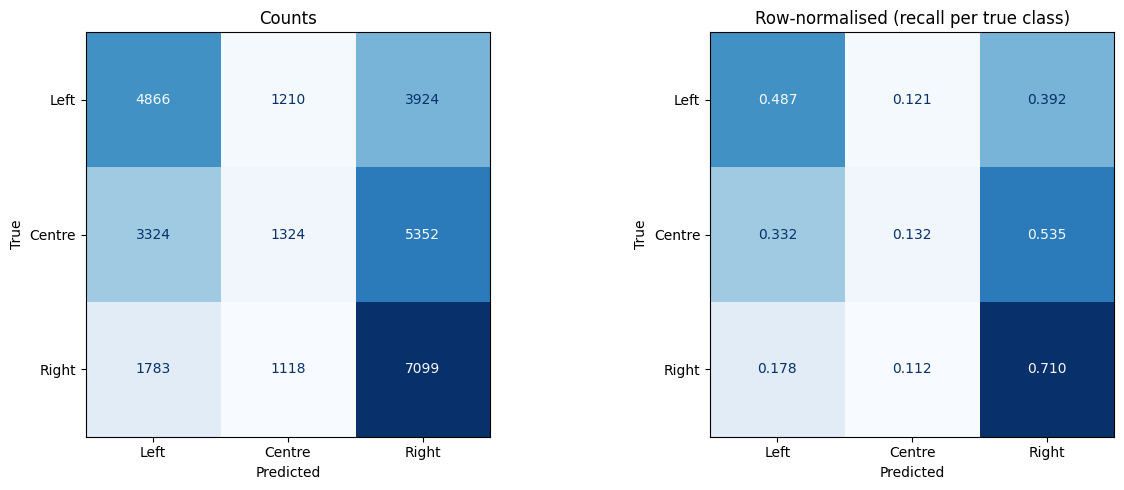

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ax[0].set_title("Counts")
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, normalize="true"),
                       display_labels=CLASSES).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".3f")
ax[1].set_title("Row-normalised (recall per true class)")
for a in ax: a.set(xlabel="Predicted", ylabel="True")
plt.tight_layout(); plt.show()

In [6]:
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

P = src[["p_left", "p_centre", "p_right"]].values
print(f"AUC-ROC (OvR, macro)   : {roc_auc_score(y_true, P, multi_class='ovr', average='macro'):.4f}")
print(f"AUC-ROC (OvR, weighted): {roc_auc_score(y_true, P, multi_class='ovr', average='weighted'):.4f}")

              precision    recall  f1-score   support

        Left     0.4879    0.4866    0.4873     10000
      Centre     0.3625    0.1324    0.1940     10000
       Right     0.4335    0.7099    0.5383     10000

    accuracy                         0.4430     30000
   macro avg     0.4280    0.4430    0.4065     30000
weighted avg     0.4280    0.4430    0.4065     30000

AUC-ROC (OvR, macro)   : 0.6578
AUC-ROC (OvR, weighted): 0.6578


### Mean predicted probability by true class

How the probability mass spreads for each true label — the soft version of the matrix above.

In [7]:
(src.groupby(src.label.map(dict(enumerate(CLASSES))))[["p_left", "p_centre", "p_right"]]
    .mean().reindex(CLASSES).rename_axis("true class").round(4))

,p_left,p_centre,p_right
true class,,,
Left,0.4846,0.1280,0.3874
Centre,0.3225,0.1527,0.5248
Right,0.1813,0.1196,0.6991


## 4. Where the errors are

Accuracy by confidence band, and by publisher. The publisher view matters because the training
labels are outlet-level, so the model can be keying on outlet style rather than framing.

In [8]:
bands = pd.cut(src.confidence, [0, .4, .5, .6, .7, .8, .9, 1.0], include_lowest=True)
(src.assign(correct=src.label == src.pred_id).groupby(bands, observed=False)
    .agg(articles=("correct", "size"), accuracy=("correct", "mean"))
    .assign(share=lambda t: (t.articles / len(src)).map("{:.1%}".format),
            accuracy=lambda t: t.accuracy.round(4)))

,articles,accuracy,share
confidence,,,
"(-0.001, 0.4]",68,0.2647,0.2%
"(0.4, 0.5]",503,0.2664,1.7%
"(0.5, 0.6]",1426,0.3303,4.8%
"(0.6, 0.7]",1461,0.3224,4.9%
"(0.7, 0.8]",1649,0.3633,5.5%
"(0.8, 0.9]",2311,0.3358,7.7%
"(0.9, 1.0]",22582,0.4791,75.3%


In [9]:
pub = (src.assign(correct=src.label == src.pred_id)
          .groupby(["slot", "publisher"])
          .agg(articles=("correct", "size"), accuracy=("correct", "mean"))
          .sort_values(["slot", "accuracy"], ascending=[True, False]).round(4))
pub

articles  accuracy
slot   publisher                    
center usatoday       2001    0.2694
       hill           6089    0.1013
       ap             1910    0.0880
left   cnn             863    0.8216
       nyt            2854    0.6889
       wpo            1199    0.3978
       dailykos       2257    0.3686
       hpo            2827    0.3120
right  wat            2814    0.8021
       breitbart      4644    0.6897
       fox            2542    0.6448

## 5. Neutral summaries — no labels, so no confusion matrix

These 10,000 texts are LLM-generated neutral summaries. They have no ground-truth bias label,
so only the model's belief can be reported, not its accuracy.

In [10]:
dist = pd.DataFrame({
    "mean_prob":    summ[["p_left", "p_centre", "p_right"]].mean().values,
    "median_prob":  summ[["p_left", "p_centre", "p_right"]].median().values,
    "argmax_count": [(summ.pred == c).sum() for c in CLASSES],
}, index=CLASSES)
dist["argmax_share"] = (dist.argmax_count / len(summ)).map("{:.1%}".format)
dist.round(4)

,mean_prob,median_prob,argmax_count,argmax_share
Left,0.3776,0.1520,3804,38.0%
Centre,0.0661,0.0050,415,4.2%
Right,0.5564,0.6832,5781,57.8%


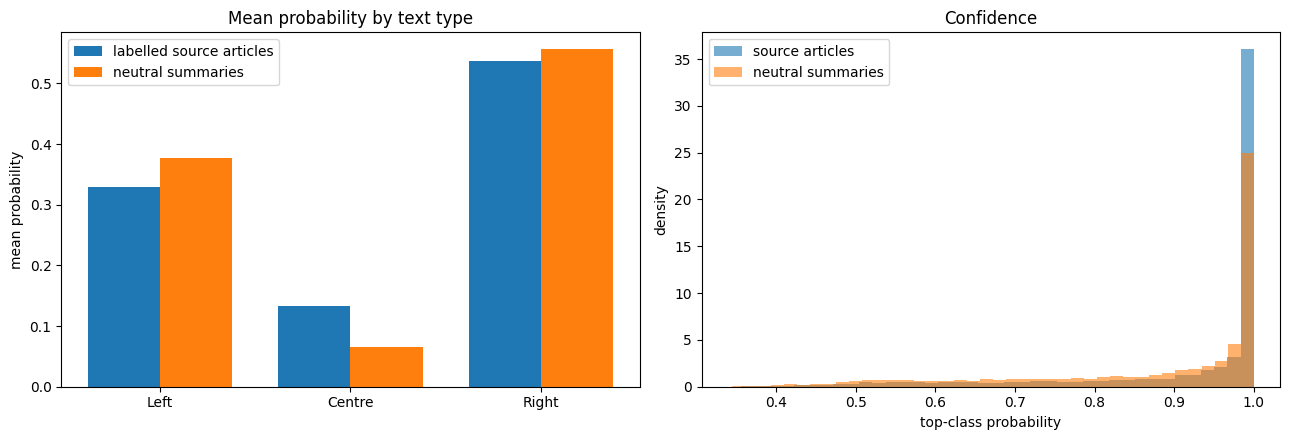

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
w = 0.38
idx = np.arange(3)
ax[0].bar(idx - w/2, [src[f"p_{k}"].mean() for k in ["left", "centre", "right"]], w, label="labelled source articles")
ax[0].bar(idx + w/2, [summ[f"p_{k}"].mean() for k in ["left", "centre", "right"]], w, label="neutral summaries")
ax[0].set(xticks=idx, xticklabels=CLASSES, ylabel="mean probability", title="Mean probability by text type")
ax[0].legend()

ax[1].hist(src.confidence, bins=40, alpha=.6, density=True, label="source articles")
ax[1].hist(summ.confidence, bins=40, alpha=.6, density=True, label="neutral summaries")
ax[1].set(xlabel="top-class probability", ylabel="density", title="Confidence")
ax[1].legend()
plt.tight_layout(); plt.show()

## Notes

- The confusion matrix in section 3 is the real evaluation: 30,000 labelled articles, ground truth
  from the outlet slot.
- Labels are **outlet-level**, inherited from the publisher, not per-article annotations. An article
  counted "wrong" may simply be an off-median piece from that outlet.
- The centre class is dominated by a few outlets (`hill`, `usatoday`, `ap`), so centre performance
  partly measures recognition of those newsrooms' house style. The per-publisher table in section 4
  is the place to look for that.
- Per-article probabilities are saved to `source_article_scores.csv` (labelled) and
  `neutral_summary_scores.csv` (unlabelled).